# Forecast model exploration — Devereaux

Side-by-side look at **every forecast model available through Open-Meteo** for one spot,
plus **CDIP buoy observations** as ground truth, before deciding what the app should ingest.

- **Swell / waves**: all wave models the Marine API serves for this location
- **Wind**: all weather models the Forecast API serves for this location
- **Buoys**: nearest active CDIP stations via ERDDAP (observations, not forecasts)

Each request includes `past_days=3` so model lines overlap the buoy record — the
overlap region is where you can judge which model tracks reality best.


In [1]:
import warnings
from datetime import datetime, timedelta, timezone
from io import StringIO
from zoneinfo import ZoneInfo

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import requests

warnings.filterwarnings('ignore')

# --- Spot under study -------------------------------------------------------
SPOT = {
    'name': 'Devereaux',
    'lat': 34.40313812226568,
    'lon': -119.8780802047039,
    'tz': 'America/Los_Angeles',
}
TZ = ZoneInfo(SPOT['tz'])
NOW = datetime.now(TZ)
PAST_DAYS = 3

# --- Chart style -------------------------------------------------------------
# Categorical palette (validated, fixed slot order — model identity keeps its
# color across every panel). Buoy observations are ink, not a series hue.
PALETTE = ['#2a78d6', '#1baf7a', '#eda100', '#008300', '#4a3aa7', '#e34948',
           '#e87ba4', '#eb6834']
INK = '#0b0b0b'
MUTED = '#52514e'

plt.rcParams.update({
    'figure.figsize': (13, 4.2),
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.color': '#e6e5e0',
    'grid.linewidth': 0.6,
    'axes.edgecolor': '#c3c2b7',
    'axes.labelcolor': MUTED,
    'text.color': INK,
    'xtick.color': MUTED,
    'ytick.color': MUTED,
    'legend.frameon': False,
    'font.size': 10,
})

print(f"Spot: {SPOT['name']} ({SPOT['lat']:.4f}, {SPOT['lon']:.4f})  |  now: {NOW:%Y-%m-%d %H:%M %Z}")

Spot: Devereaux (34.4031, -119.8781)  |  now: 2026-07-08 21:29 PDT


## 1. Fetch helpers

One function for both Open-Meteo APIs. Per model we ask for its maximum horizon and
fall back to shorter windows if the API rejects the request. Times are requested in
the spot's local timezone directly.


In [2]:
def fetch_openmeteo(base_url, model, hourly_vars, max_days, extra=None,
                   lat=None, lon=None):
    """Return a DataFrame indexed by local time, or None. Tries decreasing horizons."""
    for days in (max_days, 10, 7, 4, 2):
        if days > max_days:
            continue
        params = {
            'latitude': lat if lat is not None else SPOT['lat'],
            'longitude': lon if lon is not None else SPOT['lon'],
            'hourly': ','.join(hourly_vars),
            'models': model,
            'forecast_days': days,
            'past_days': PAST_DAYS,
            'timezone': SPOT['tz'],
        }
        if extra:
            params.update(extra)
        try:
            r = requests.get(base_url, params=params, timeout=45)
            if r.status_code != 200:
                continue
            js = r.json()
            hourly = js.get('hourly') or {}
            if not hourly.get('time'):
                continue
            df = pd.DataFrame(hourly)
            df['time'] = pd.to_datetime(df['time']).dt.tz_localize(TZ, ambiguous='NaT',
                                                                   nonexistent='NaT')
            df = df.set_index('time').dropna(how='all')
            # drop variables the model doesn't provide (all-null columns)
            df = df.dropna(axis=1, how='all')
            if len(df):
                # grid cell the API actually selected (not the requested point)
                df.attrs['cell_lat'] = js.get('latitude')
                df.attrs['cell_lon'] = js.get('longitude')
                return df
        except requests.RequestException:
            continue
    return None


def summarize(dfs):
    rows = []
    for label, df in dfs.items():
        if df is None:
            rows.append({'model': label, 'status': 'UNAVAILABLE'})
            continue
        fut = df[df.index >= NOW]
        rows.append({
            'model': label,
            'status': 'ok',
            'points': len(df),
            'variables': ', '.join(c for c in df.columns),
            'horizon_days': round((df.index.max() - NOW).total_seconds() / 86400, 1),
        })
    return pd.DataFrame(rows).set_index('model')

## 2. Wave / swell models (Open-Meteo Marine API)

Model names verified against the current API (several changed since earlier exploration:
`gfs_wave025` → `ncep_gfswave025`; DWD `ewam` has no coverage here). `era5_ocean` is
reanalysis (history, not forecast) so it is excluded.

Variables: primary swell (height/period/direction), **combined** significant wave height
(`wave_height` — what a buoy actually measures), and wind-wave height.


In [3]:
MARINE_URL = 'https://marine-api.open-meteo.com/v1/marine'
MARINE_VARS = ['swell_wave_height', 'swell_wave_period', 'swell_wave_direction',
               'wave_height', 'wind_wave_height']

# label -> (api model name, max forecast days)  — dict order fixes palette slots
MARINE_MODELS = {
    'MFWAM 8km (app today)': ('meteofrance_wave', 10),
    'ECMWF WAM 9km':         ('ecmwf_wam',        15),
    'ECMWF WAM 25km':        ('ecmwf_wam025',     15),
    'GFS Wave 25km':         ('ncep_gfswave025',  16),
    'DWD GWAM 25km':         ('gwam',              8),
}

marine = {}
for label, (model, days) in MARINE_MODELS.items():
    marine[label] = fetch_openmeteo(MARINE_URL, model, MARINE_VARS, days,
                                    extra={'cell_selection': 'sea'})
    print(f"{label:24s} {'ok, ' + str(len(marine[label])) + ' h' if marine[label] is not None else 'UNAVAILABLE'}")

summarize(marine)

MFWAM 8km (app today)    ok, 308 h


ECMWF WAM 9km            ok, 432 h


ECMWF WAM 25km           ok, 432 h


GFS Wave 25km            ok, 456 h


DWD GWAM 25km            ok, 264 h


,status,points,variables,horizon_days
model,,,,
MFWAM 8km (app today),ok,308,"swell_wave_height, swell_wave_period, swell_wa...",8.9
ECMWF WAM 9km,ok,432,wave_height,14.1
ECMWF WAM 25km,ok,432,wave_height,14.1
GFS Wave 25km,ok,456,"swell_wave_height, swell_wave_period, swell_wa...",15.1
DWD GWAM 25km,ok,264,"swell_wave_height, swell_wave_period, swell_wa...",7.1


## 3. CDIP buoy observations (ERDDAP)

Nearest active stations to the spot, last 3 days of observed significant wave height
(**Hs**), peak period (**Tp**) and peak direction (**Dp**). Buoys measure the *total* sea
state → compare them against models' `wave_height`, not the swell partition alone.


In [4]:
ERDDAP = 'https://erddap.cdip.ucsd.edu/erddap/tabledap/wave_agg.csv'

def fetch_cdip(n_stations=2):
    start = (datetime.now(timezone.utc) - timedelta(days=PAST_DAYS)).strftime('%Y-%m-%dT%H:%M:%SZ')
    query = ('?station_id,time,latitude,longitude,waveHs,waveTp,waveDp'
             f'&time>={start}')
    r = requests.get(ERDDAP + query, timeout=90)
    r.raise_for_status()
    df = pd.read_csv(StringIO(r.text), skiprows=[1])  # row 1 = units
    df['time'] = pd.to_datetime(df['time'], utc=True).dt.tz_convert(TZ)

    # rank stations by distance to the spot
    pos = df.groupby('station_id')[['latitude', 'longitude']].last()
    dist = ((pos['latitude'] - SPOT['lat']) ** 2 +
            (pos['longitude'] - SPOT['lon']) ** 2) ** 0.5 * 111  # ~km
    nearest = dist.sort_values().head(n_stations)

    out = {}
    for sid, d_km in nearest.items():
        sdf = df[df['station_id'] == sid].set_index('time').sort_index()
        out[f'CDIP {sid} ({d_km:.0f} km)'] = sdf
    return out

try:
    buoys = fetch_cdip()
    for k, v in buoys.items():
        print(f'{k}: {len(v)} obs, latest {v.index.max():%m-%d %H:%M}')
except Exception as e:
    buoys = {}
    print('CDIP unavailable right now:', e)

CDIP 203 (79 km): 143 obs, latest 07-08 20:30
CDIP 71 (100 km): 143 obs, latest 07-08 20:30


## 4. Swell & wave height — all models vs buoys

- **Left of the dashed line** = the past: model lines should hug the black buoy dots.
- **Right** = forecast: where models disagree is your uncertainty.


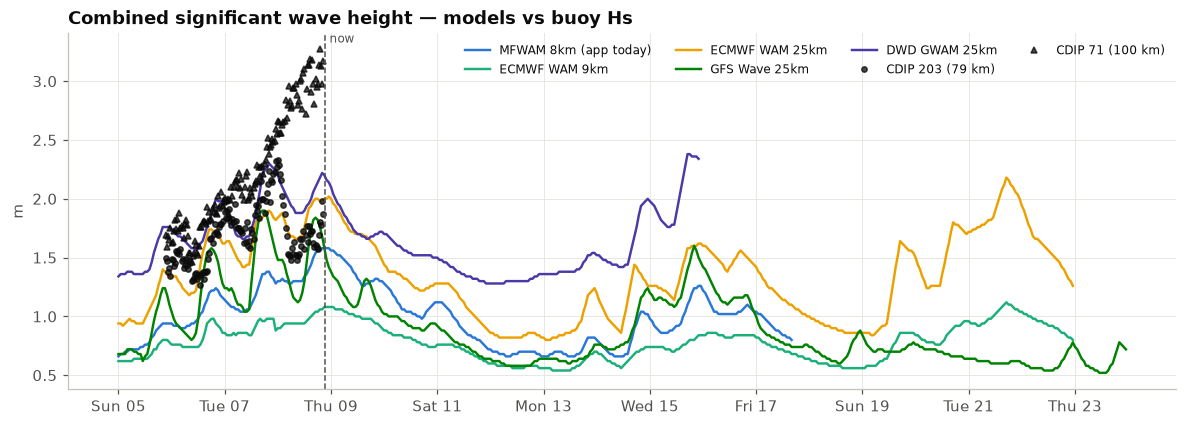

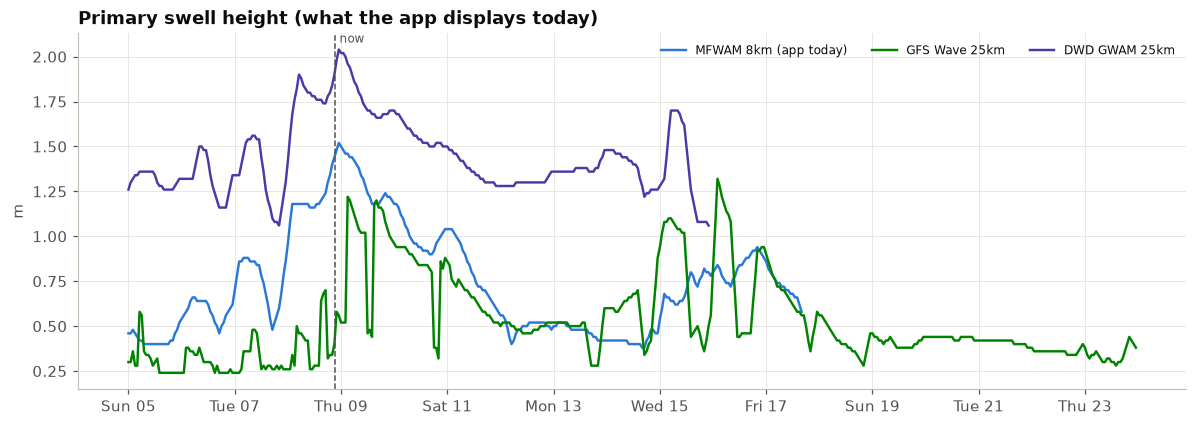

In [5]:
def plot_models(dfs, var, ylabel, title, buoy_var=None, ax=None, direction=False):
    if ax is None:
        _, ax = plt.subplots()
    for (label, df), color in zip(dfs.items(), PALETTE):
        if df is None or var not in df.columns:
            continue
        if direction:
            ax.plot(df.index, df[var], lw=0, marker='.', ms=3, color=color, label=label)
        else:
            ax.plot(df.index, df[var], lw=1.6, color=color, label=label)
    if buoy_var:
        for mark, (label, bdf) in zip(('o', '^'), buoys.items()):
            ax.plot(bdf.index, bdf[buoy_var], lw=0, marker=mark, ms=3.5,
                    color=INK, alpha=0.75, label=label)
    ax.axvline(NOW, color=MUTED, lw=1, ls='--')
    ax.text(NOW, ax.get_ylim()[1], ' now', color=MUTED, fontsize=8, va='top')
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc='left', fontweight='bold')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %d', tz=TZ))
    ax.legend(ncols=4, fontsize=8, loc='upper right')
    if direction:
        ax.set_ylim(0, 360)
        ax.set_yticks([0, 90, 180, 270, 360], ['N', 'E', 'S', 'W', 'N'])
    return ax

plot_models(marine, 'wave_height', 'm',
            'Combined significant wave height — models vs buoy Hs', buoy_var='waveHs')
plt.show()

plot_models(marine, 'swell_wave_height', 'm',
            'Primary swell height (what the app displays today)')
plt.show()

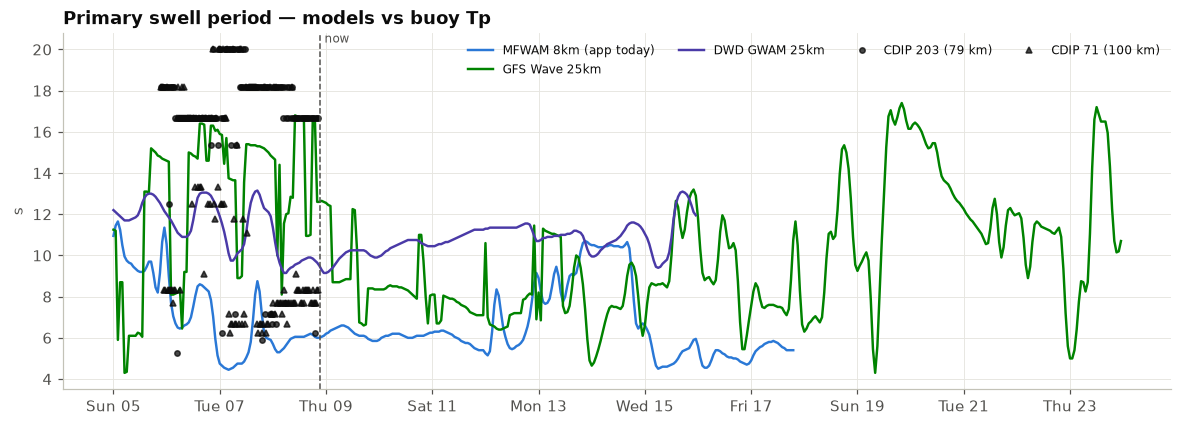

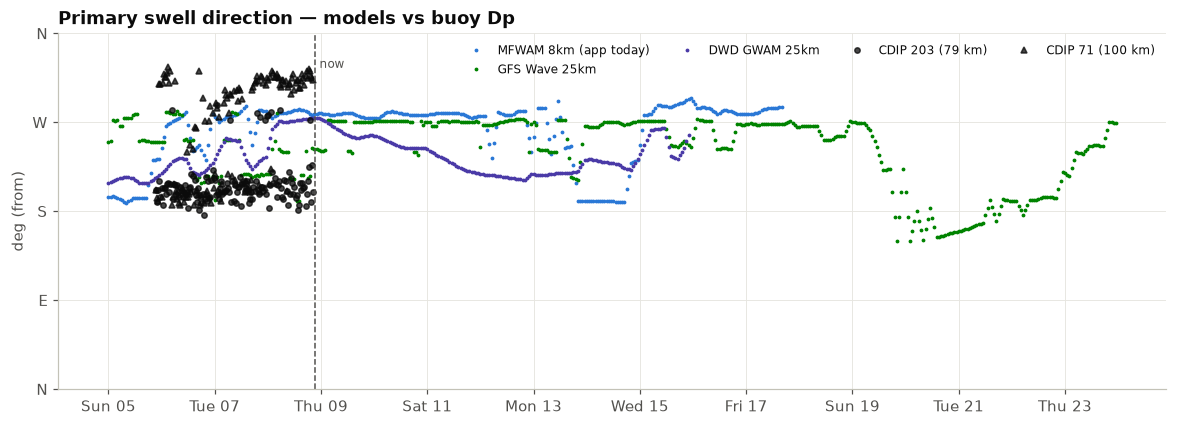

In [6]:
plot_models(marine, 'swell_wave_period', 's',
            'Primary swell period — models vs buoy Tp', buoy_var='waveTp')
plt.show()

plot_models(marine, 'swell_wave_direction', 'deg (from)',
            'Primary swell direction — models vs buoy Dp', buoy_var='waveDp',
            direction=True)
plt.show()

### Zoom: the validation window (past 3 days + next 2)

The only region where "which model is right" is directly checkable.


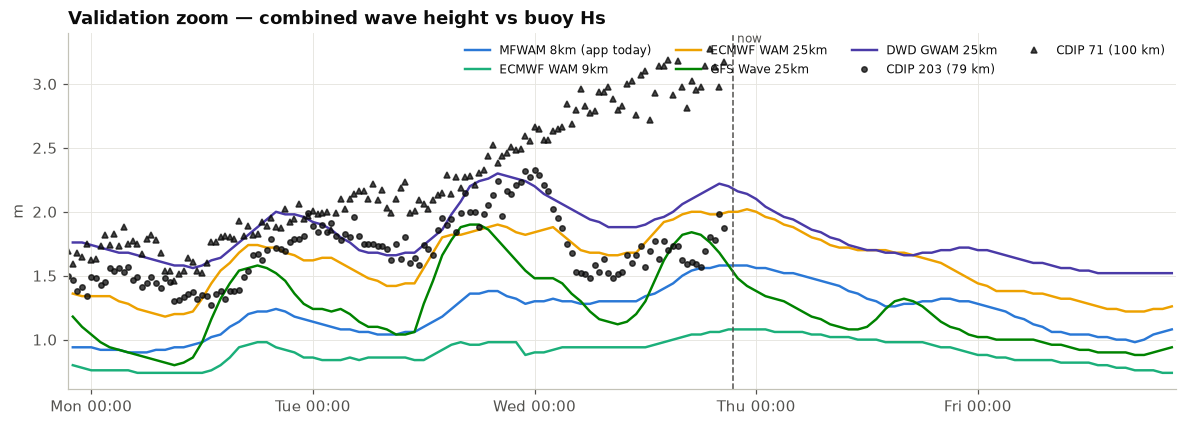

In [7]:
window = (NOW - timedelta(days=PAST_DAYS), NOW + timedelta(days=2))
zoom = {k: (v[(v.index >= window[0]) & (v.index <= window[1])] if v is not None else None)
        for k, v in marine.items()}
ax = plot_models(zoom, 'wave_height', 'm',
                 'Validation zoom — combined wave height vs buoy Hs', buoy_var='waveHs')
ax.set_xlim(*window)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M', tz=TZ))
plt.show()

### Apples-to-apples at the buoys — observations, CDIP MOP forecast, global models

The panels above sample models **at Devereaux** (inside the Channel Islands' swell
shadow) while the buoys float 79–100 km away in open water — so the buoy/model gap
mixes location difference with model error.

Here, per buoy: its **observed Hs** (black), **CDIP's MOP forecast at that exact site**
(red — the same forecast shown on cdip.ucsd.edu station pages, ECMWF-forced nearshore
model, ~8-day horizon, via THREDDS/OPeNDAP), and the **global models re-fetched at the
buoy's coordinates**. Left of the dashed line, every line is checkable against reality.


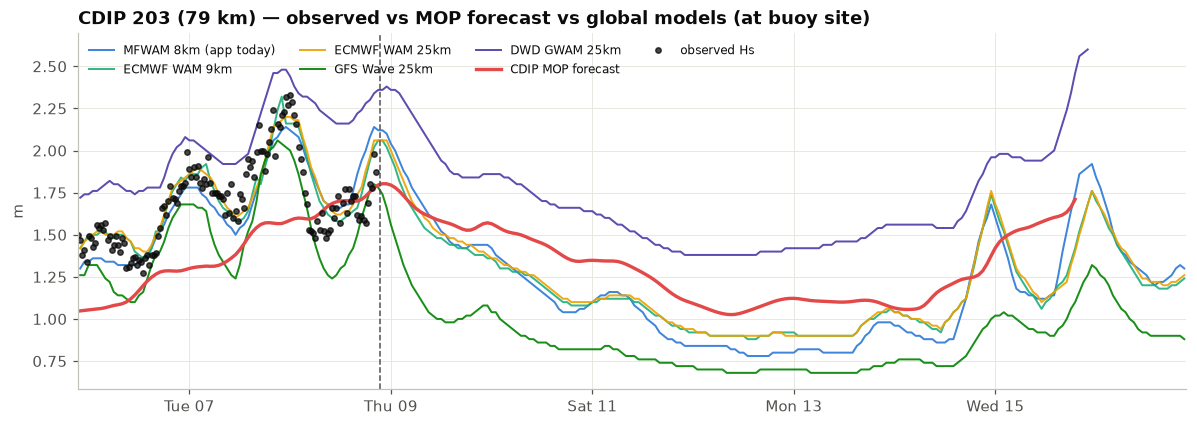

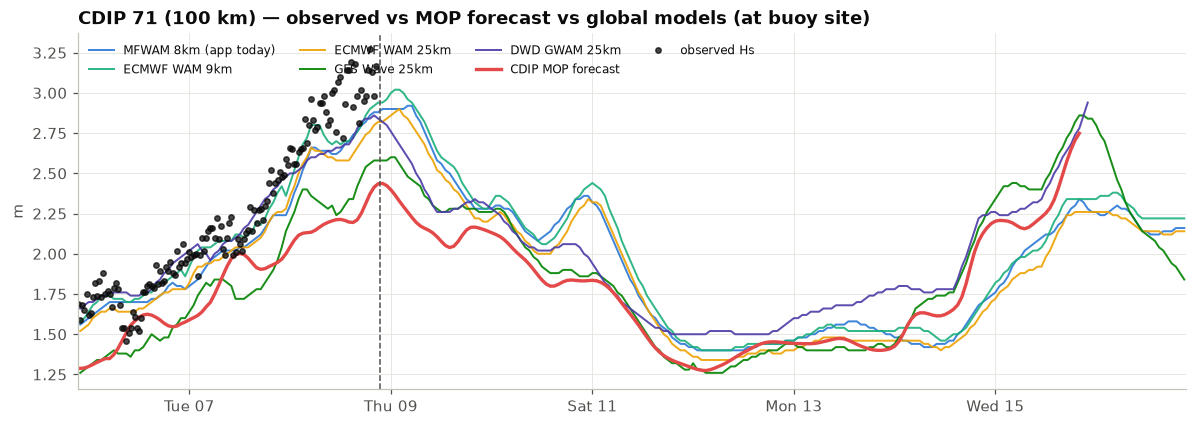

In [8]:
import numpy as np
import xarray as xr

MOP_URL = 'https://thredds.cdip.ucsd.edu/thredds/dodsC/cdip/model/MOP_validation/BP{sid:03d}_forecast.nc'

def fetch_mop_forecast(station_id, start):
    """CDIP MOP forecast Hs at a buoy site, sliced from `start` (lazy OPeNDAP)."""
    ds = xr.open_dataset(MOP_URL.format(sid=int(station_id)))
    t = ds['waveTime'].values
    i0 = int(np.searchsorted(t, np.datetime64(start.astimezone(timezone.utc).replace(tzinfo=None))))
    hs = ds['waveHs'].isel(waveTime=slice(i0, None)).values
    idx = pd.to_datetime(t[i0:], utc=True).tz_convert(TZ)
    ds.close()
    return pd.Series(hs, index=idx, name='waveHs')

MOP_RED = '#e34948'  # reserved slot: MOP forecast keeps this color everywhere

for bkey, bdf in buoys.items():
    sid = bdf['station_id'].iloc[-1]
    bpos = bdf[['latitude', 'longitude']].iloc[-1]

    at_buoy = {}
    for label, (model, days) in MARINE_MODELS.items():
        at_buoy[label] = fetch_openmeteo(
            MARINE_URL, model, ['wave_height'], min(days, 10),
            extra={'cell_selection': 'sea'},
            lat=bpos['latitude'], lon=bpos['longitude'])

    try:
        mop = fetch_mop_forecast(sid, window[0])
    except Exception as e:
        mop = None
        print(f'MOP unavailable for {bkey}: {e}')

    xmax = NOW + timedelta(days=8)
    _, ax = plt.subplots()
    for (label, df), color in zip(at_buoy.items(), PALETTE):
        if df is None or 'wave_height' not in df.columns:
            continue
        d = df[(df.index >= window[0]) & (df.index <= xmax)]
        ax.plot(d.index, d['wave_height'], lw=1.3, color=color, alpha=0.9, label=label)
    if mop is not None:
        m = mop[(mop.index >= window[0]) & (mop.index <= xmax)]
        ax.plot(m.index, m.values, lw=2.2, color=MOP_RED, label='CDIP MOP forecast')
    ax.plot(bdf.index, bdf['waveHs'], lw=0, marker='o', ms=3.5, color=INK,
            alpha=0.75, label='observed Hs')
    ax.axvline(NOW, color=MUTED, lw=1, ls='--')
    ax.set_ylabel('m')
    ax.set_title(f'{bkey} — observed vs MOP forecast vs global models (at buoy site)',
                 loc='left', fontweight='bold')
    ax.set_xlim(window[0], xmax)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %d', tz=TZ))
    ax.legend(ncols=4, fontsize=8, loc='upper left')
    plt.show()

### The nearshore answer — CDIP MOP 1 km grid *at the spot*

Same extraction as `swell_forecast_extractor.py`: open the MOP California forecast grid
(`CA_0.01_forecast.nc`, ~1 km), take the nearest grid point to the spot, and fall back
to the closest *valid* point if that cell is NaN. This is the only source in the whole
notebook that models the water Devereaux actually sits in — behind the Channel Islands,
after refraction. Note its horizon: the grid forecast is short (~4 days, 6-hourly),
unlike the 8-day MOP station product above.


In [9]:
MOP_GRID_URL = 'https://thredds.cdip.ucsd.edu/thredds/dodsC/cdip/model/MOP_grids/CA_0.01_forecast.nc'

def fetch_mop_grid_point(lat, lon, box_deg=0.06):
    """MOP forecast at the nearest valid ~1 km grid point + nearby valid points."""
    ds = xr.open_dataset(MOP_GRID_URL)
    lats = ds['metaLatitude'].values
    lons = ds['metaLongitude'].values
    li = int(np.abs(lats - lat).argmin())
    lj = int(np.abs(lons - lon).argmin())

    hs0 = ds['waveHs'].isel(waveTime=0).values  # 2-D validity mask
    valid = ~np.isnan(hs0)
    if np.isnan(hs0[li, lj]):
        vi, vj = np.nonzero(valid)
        d2 = (lats[vi] - lat) ** 2 + (np.cos(np.radians(lat)) * (lons[vj] - lon)) ** 2
        k = int(d2.argmin())
        li, lj = int(vi[k]), int(vj[k])

    idx = pd.to_datetime(ds['waveTime'].values, utc=True).tz_convert(TZ)
    df = pd.DataFrame({
        'wave_height': ds['waveHs'].isel(metaLatitude=li, metaLongitude=lj).values,
        'peak_period': ds['waveTp'].isel(metaLatitude=li, metaLongitude=lj).values,
        'direction': ds['waveDp'].isel(metaLatitude=li, metaLongitude=lj).values,
    }, index=idx)
    df.attrs['cell_lat'] = float(lats[li])
    df.attrs['cell_lon'] = float(lons[lj])

    # valid grid points near the spot, to draw the 1 km nearshore band on the map
    ib = np.nonzero(np.abs(lats - lat) < box_deg)[0]
    jb = np.nonzero(np.abs(lons - lon) < box_deg * 1.4)[0]
    sub = valid[np.ix_(ib, jb)]
    pts = [(float(lats[ib[a]]), float(lons[jb[b]]))
           for a, b in zip(*np.nonzero(sub))][:600]
    ds.close()
    return df, pts

try:
    mop_grid, mop_pts = fetch_mop_grid_point(SPOT['lat'], SPOT['lon'])
    print(f"MOP grid point ({mop_grid.attrs['cell_lat']:.3f}, {mop_grid.attrs['cell_lon']:.3f}) — "
          f"{len(mop_grid)} steps to {mop_grid.index.max():%a %d %H:%M}, "
          f"{len(mop_pts)} valid ~1km points nearby")
except Exception as e:
    mop_grid, mop_pts = None, []
    print('MOP grid unavailable:', e)
mop_grid.head() if mop_grid is not None else None

MOP grid point (34.400, -119.880) — 16 steps to Sun 12 12:00, 125 valid ~1km points nearby


,wave_height,peak_period,direction
2026-07-08 18:00:00-07:00,0.477904,18.181818,215.148285
2026-07-09 00:00:00-07:00,0.534998,10.000000,238.445084
2026-07-09 06:00:00-07:00,0.547446,10.000000,238.933075
2026-07-09 12:00:00-07:00,0.520893,10.000000,237.916016
2026-07-09 18:00:00-07:00,0.515097,9.090909,243.051971


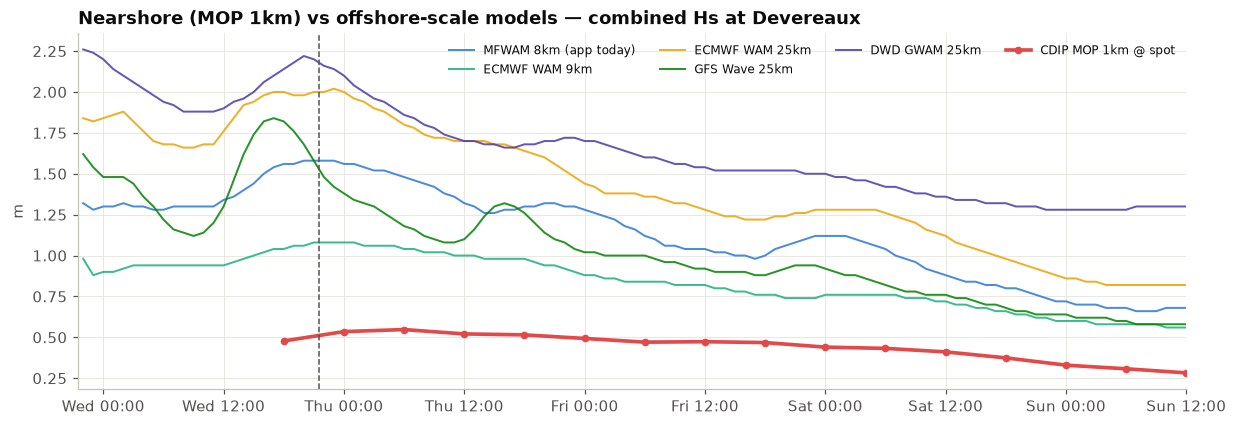

In [10]:
if mop_grid is not None:
    xmax2 = mop_grid.index.max()
    _, ax = plt.subplots()
    for (label, df), color in zip(marine.items(), PALETTE):
        if df is None:
            continue
        d = df[(df.index >= NOW - timedelta(days=1)) & (df.index <= xmax2)]
        ax.plot(d.index, d['wave_height'], lw=1.3, color=color, alpha=0.85, label=label)
    ax.plot(mop_grid.index, mop_grid['wave_height'], lw=2.4, marker='o', ms=4,
            color=MOP_RED, label='CDIP MOP 1km @ spot')
    ax.axvline(NOW, color=MUTED, lw=1, ls='--')
    ax.set_ylabel('m')
    ax.set_title('Nearshore (MOP 1km) vs offshore-scale models — combined Hs at Devereaux',
                 loc='left', fontweight='bold')
    ax.set_xlim(NOW - timedelta(days=1), xmax2)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M', tz=TZ))
    ax.legend(ncols=4, fontsize=8, loc='upper right')
    plt.show()

## 5. Wind models (Open-Meteo Forecast API)

The high-resolution US models are the interesting ones for coastal wind:
**HRRR 3 km** (only ~2 days) and **NBM 2.5 km** (calibrated blend, 11 days).


In [11]:
WIND_URL = 'https://api.open-meteo.com/v1/forecast'
WIND_VARS = ['wind_speed_10m', 'wind_direction_10m']

WIND_MODELS = {
    'GFS seamless (app today)': ('gfs_seamless',   16),
    'ECMWF IFS 25km':           ('ecmwf_ifs025',   10),
    'ICON seamless':            ('icon_seamless',   8),
    'GEM global':               ('gem_global',     10),
    'NBM 2.5km (blend)':        ('ncep_nbm_conus', 11),
    'HRRR 3km':                 ('gfs_hrrr',        2),
}

wind = {}
for label, (model, days) in WIND_MODELS.items():
    wind[label] = fetch_openmeteo(WIND_URL, model, WIND_VARS, days,
                                  extra={'wind_speed_unit': 'kn'})
    print(f"{label:26s} {'ok, ' + str(len(wind[label])) + ' h' if wind[label] is not None else 'UNAVAILABLE'}")

summarize(wind)

GFS seamless (app today)   ok, 456 h


ECMWF IFS 25km             ok, 312 h


ICON seamless              ok, 264 h


GEM global                 ok, 312 h


NBM 2.5km (blend)          ok, 336 h


HRRR 3km                   ok, 120 h


,status,points,variables,horizon_days
model,,,,
GFS seamless (app today),ok,456,"wind_speed_10m, wind_direction_10m",15.1
ECMWF IFS 25km,ok,312,"wind_speed_10m, wind_direction_10m",9.1
ICON seamless,ok,264,"wind_speed_10m, wind_direction_10m",7.1
GEM global,ok,312,"wind_speed_10m, wind_direction_10m",9.1
NBM 2.5km (blend),ok,336,"wind_speed_10m, wind_direction_10m",10.1
HRRR 3km,ok,120,"wind_speed_10m, wind_direction_10m",1.1


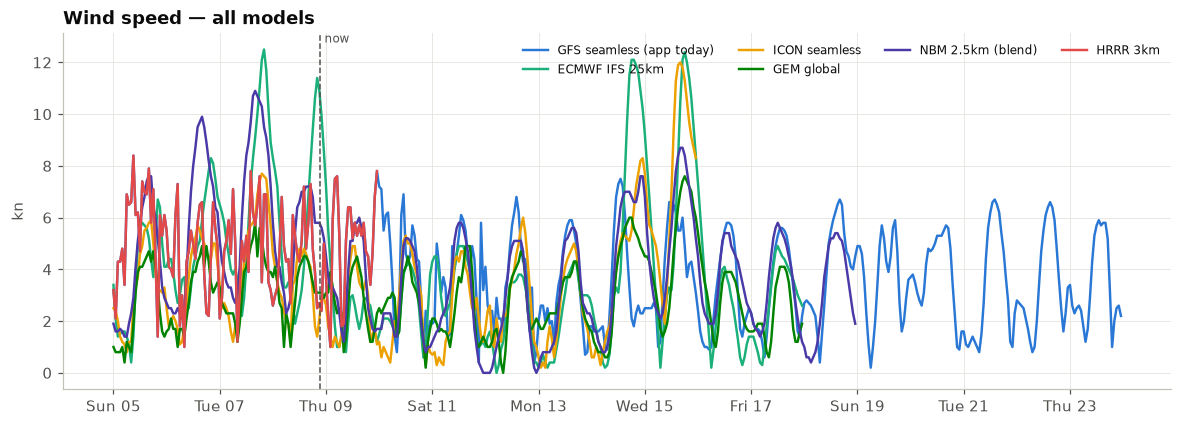

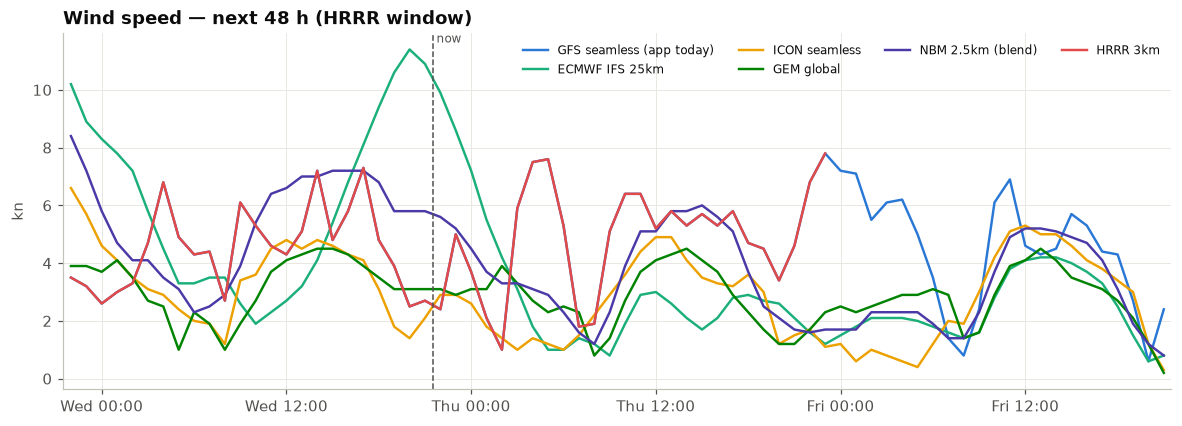

In [12]:
plot_models(wind, 'wind_speed_10m', 'kn', 'Wind speed — all models')
plt.show()

# Zoom on the next 48h where HRRR participates
wzoom = {k: (v[(v.index >= NOW - timedelta(days=1)) & (v.index <= NOW + timedelta(days=2))]
             if v is not None else None) for k, v in wind.items()}
ax = plot_models(wzoom, 'wind_speed_10m', 'kn', 'Wind speed — next 48 h (HRRR window)')
ax.set_xlim(NOW - timedelta(days=1), NOW + timedelta(days=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M', tz=TZ))
plt.show()

## 6. Spatial extraction map (folium)

Recreates the old exploration's grid maps, all in one layered map:

- **Model grids** (toggle in the layer control, MFWAM on by default): the lattice of
  each wave model around the spot, with the **cell the API actually selected**
  highlighted. ECMWF's native grid is octahedral, so its lattice here is approximate.
- **Time series live in the map**: click the selected cell of a model for that model's
  extracted series, the red spot marker for the all-model comparison, or a buoy for
  its observations + CDIP MOP forecast.


In [13]:
import base64
from io import BytesIO

import folium

def series_png_html(title, layers, width=460):
    """Render layers into a small PNG and wrap as popup HTML.

    layers: list of (label, series, kind, color) with kind in {'line', 'dots'}.
    """
    fig, ax = plt.subplots(figsize=(5.4, 2.1), dpi=88)
    for label, s, kind, color in layers:
        if s is None or len(s) == 0:
            continue
        if kind == 'dots':
            ax.plot(s.index, s.values, lw=0, marker='o', ms=2.5, color=color, label=label)
        else:
            ax.plot(s.index, s.values, lw=1.4, color=color, label=label)
    ax.axvline(NOW, color=MUTED, lw=0.8, ls='--')
    ax.set_title(title, loc='left', fontsize=9, fontweight='bold')
    ax.set_ylabel('m', fontsize=8)
    ax.tick_params(labelsize=7)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %d', tz=TZ))
    ax.legend(fontsize=6, ncols=3, frameon=False)
    buf = BytesIO()
    fig.savefig(buf, format='png', bbox_inches='tight')
    plt.close(fig)
    b64 = base64.b64encode(buf.getvalue()).decode()
    return f'<img width="{width}" src="data:image/png;base64,{b64}">'

# Approximate lattice spacing (deg) per model — for drawing only
MODEL_RES_DEG = {
    'MFWAM 8km (app today)': 1 / 12,
    'ECMWF WAM 9km': 0.09,       # octahedral grid — approximate
    'ECMWF WAM 25km': 0.25,
    'GFS Wave 25km': 0.25,
    'DWD GWAM 25km': 0.25,
}


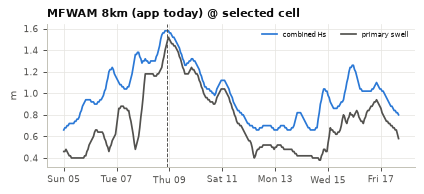
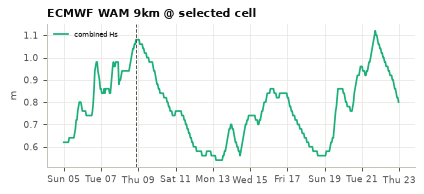
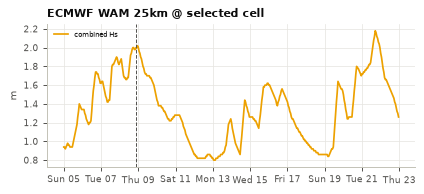
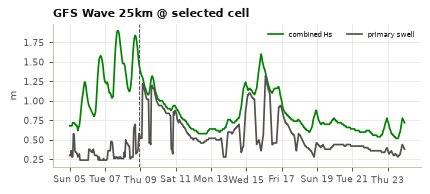
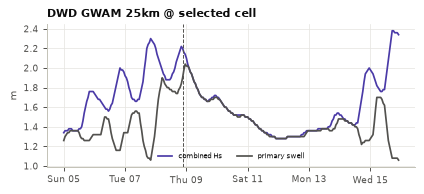
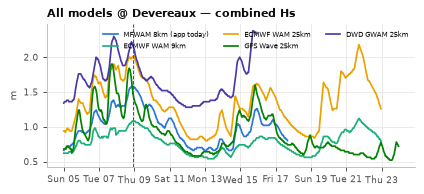
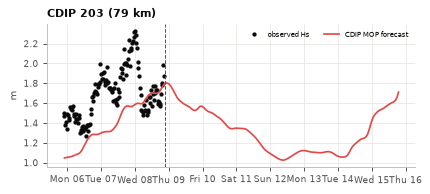
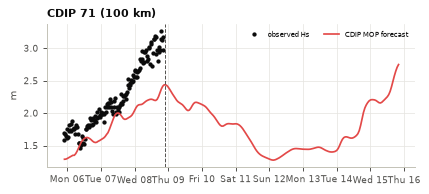
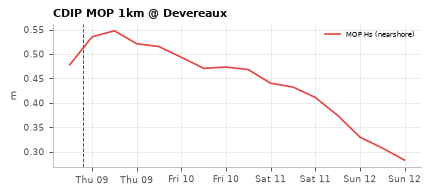

In [14]:
m = folium.Map(location=[SPOT['lat'], SPOT['lon']], zoom_start=10, tiles=None,
               control_scale=True)
folium.TileLayer(
    'https://server.arcgisonline.com/ArcGIS/rest/services/Ocean/World_Ocean_Base/MapServer/tile/{z}/{y}/{x}',
    attr='Esri, GEBCO, NOAA', name='Ocean base').add_to(m)
folium.TileLayer(
    'https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
    attr='Esri, USGS', name='Satellite', opacity=0.6).add_to(m)

for (label, df), color in zip(marine.items(), PALETTE):
    if df is None or 'cell_lat' not in df.attrs:
        continue
    res = MODEL_RES_DEG[label]
    clat, clon = df.attrs['cell_lat'], df.attrs['cell_lon']
    fg = folium.FeatureGroup(name=f'{label} grid', show=(label.startswith('MFWAM')))

    # lattice around the selected cell (drawing only — centers are exact for the
    # selected cell, neighbors assume a regular grid)
    for i in range(-3, 4):
        for j in range(-3, 4):
            la, lo = clat + i * res, clon + j * res
            folium.Rectangle(
                bounds=[[la - res / 2, lo - res / 2], [la + res / 2, lo + res / 2]],
                color=color, weight=1, fill=False, opacity=0.45).add_to(fg)

    # the selected cell, with that model's extracted series in the popup
    layers = [('combined Hs', df.get('wave_height'), 'line', color),
              ('primary swell', df.get('swell_wave_height'), 'line', MUTED)]
    folium.Rectangle(
        bounds=[[clat - res / 2, clon - res / 2], [clat + res / 2, clon + res / 2]],
        color=color, weight=2.5, fill=True, fill_color=color, fill_opacity=0.35,
        tooltip=f'{label} — selected cell ({clat:.3f}, {clon:.3f})',
        popup=folium.Popup(series_png_html(f'{label} @ selected cell', layers),
                           max_width=500),
    ).add_to(fg)
    fg.add_to(m)

# Spot marker — all models at the extraction point
spot_layers = [(label, df.get('wave_height'), 'line', color)
               for (label, df), color in zip(marine.items(), PALETTE) if df is not None]
folium.Marker(
    [SPOT['lat'], SPOT['lon']],
    icon=folium.Icon(color='red', icon='star'),
    tooltip=f"{SPOT['name']} (extraction point)",
    popup=folium.Popup(series_png_html(f"All models @ {SPOT['name']} — combined Hs",
                                       spot_layers), max_width=500),
).add_to(m)

# Buoys — observations + CDIP MOP forecast
for bkey, bdf in buoys.items():
    sid = bdf['station_id'].iloc[-1]
    bpos = bdf[['latitude', 'longitude']].iloc[-1]
    try:
        mop = fetch_mop_forecast(sid, window[0])
    except Exception:
        mop = None
    layers = [('observed Hs', bdf['waveHs'], 'dots', INK),
              ('CDIP MOP forecast', mop, 'line', MOP_RED)]
    folium.CircleMarker(
        [bpos['latitude'], bpos['longitude']], radius=7, color=INK,
        fill=True, fill_color='#ffffff', fill_opacity=0.9,
        tooltip=bkey,
        popup=folium.Popup(series_png_html(bkey, layers), max_width=500),
    ).add_to(m)

# CDIP MOP ~1 km grid: the nearshore band of valid points + the selected cell
if mop_grid is not None:
    fg = folium.FeatureGroup(name='CDIP MOP 1km grid', show=True)
    for la, lo in mop_pts:
        folium.CircleMarker([la, lo], radius=2, color=MOP_RED, weight=1,
                            fill=True, fill_opacity=0.5, opacity=0.5).add_to(fg)
    mop_layers = [('MOP Hs (nearshore)', mop_grid['wave_height'], 'line', MOP_RED)]
    folium.CircleMarker(
        [mop_grid.attrs['cell_lat'], mop_grid.attrs['cell_lon']],
        radius=7, color=MOP_RED, weight=3, fill=True, fill_color=MOP_RED,
        fill_opacity=0.9,
        tooltip=f"CDIP MOP selected point ({mop_grid.attrs['cell_lat']:.3f}, "
                f"{mop_grid.attrs['cell_lon']:.3f})",
        popup=folium.Popup(series_png_html('CDIP MOP 1km @ Devereaux', mop_layers),
                           max_width=500),
    ).add_to(fg)
    fg.add_to(m)

folium.LayerControl(collapsed=False).add_to(m)
m.save('spatial_extraction_map.html')  # standalone copy, opens in any browser
m

### MOP 1 km forecast gradient — Santa Barbara Channel

The gradient map: every valid MOP grid point in the region, colored by **forecast Hs**.
This is where the 1 km model earns its keep visually — watch the wave height collapse
from the exposed west-facing coast into the Channel Islands' shadow where Devereaux
and C St. sit. Two forecast times as toggleable layers (see the layer control), color
scale shared.


In [15]:
import branca.colormap as bcm
from matplotlib.colors import LinearSegmentedColormap

# Classic surf-forecast wave-height scale (Surfline/Windy style):
# blue -> cyan -> green -> yellow -> orange -> red -> magenta -> purple -> black
SURF_COLORS = ['#1e50a0', '#2e86d1', '#31c3ef', '#57e86b', '#f5f04f',
               '#ffa726', '#f4442e', '#c2185b', '#8e24aa', '#4a148c', '#212121']
surf_cmap = LinearSegmentedColormap.from_list('surf', SURF_COLORS)

GRAD_BBOX = {'lat': (33.70, 34.62), 'lon': (-120.75, -119.00)}

def mop_hs_slice(when_local, bbox=None):
    """(valid_time, lats, lons, 2-D Hs) for the MOP grid inside bbox."""
    bbox = bbox or GRAD_BBOX
    ds = xr.open_dataset(MOP_GRID_URL)
    lats = ds['metaLatitude'].values
    lons = ds['metaLongitude'].values
    t = pd.to_datetime(ds['waveTime'].values, utc=True).tz_convert(TZ)
    k = int(np.abs(t - when_local).argmin())
    i0, i1 = np.searchsorted(lats, bbox['lat'])
    j0, j1 = np.searchsorted(lons, bbox['lon'])
    hs = ds['waveHs'].isel(waveTime=k, metaLatitude=slice(i0, i1),
                           metaLongitude=slice(j0, j1)).values
    ds.close()
    return t[k], lats[i0:i1], lons[j0:j1], hs

targets = [(NOW + timedelta(days=1)).replace(hour=8, minute=0),
           (NOW + timedelta(days=3)).replace(hour=8, minute=0)]
slices = [mop_hs_slice(when) for when in targets]
vmax = float(max(np.nanmax(hs) for _, _, _, hs in slices))
for vt, _, _, hs in slices:
    print(f'{vt:%a %d %H:%M}: {int(np.isfinite(hs).sum())} points, '
          f'Hs {np.nanmin(hs):.2f}–{np.nanmax(hs):.2f} m')

Thu 09 06:00: 11706 points, Hs 0.03–2.72 m
Sat 11 06:00: 11706 points, Hs 0.02–2.16 m


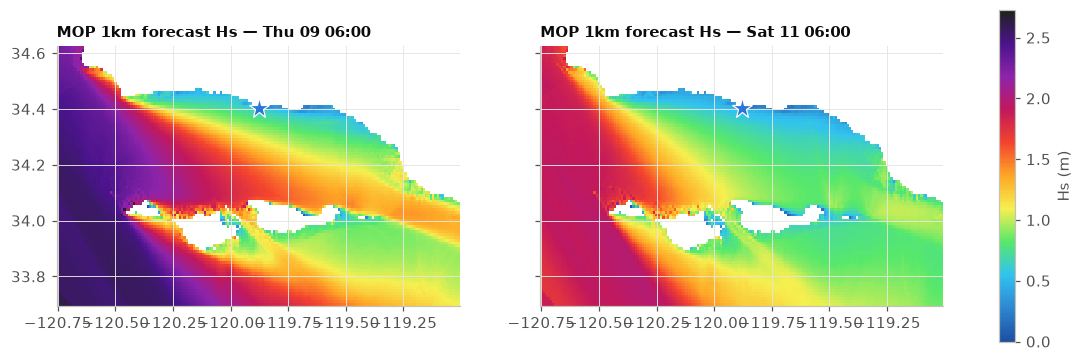

In [16]:
# Static companion (same data, matplotlib) — renders in the saved notebook
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, (vt, la, lo, hs) in zip(axes, slices):
    pm = ax.pcolormesh(lo, la, hs, cmap=surf_cmap, vmin=0, vmax=vmax)
    ax.plot(SPOT['lon'], SPOT['lat'], marker='*', ms=14, color='#2a78d6',
            mec='white', mew=0.8)
    ax.set_title(f'MOP 1km forecast Hs — {vt:%a %d %H:%M}', loc='left',
                 fontweight='bold', fontsize=10)
    ax.set_aspect(1 / np.cos(np.radians(SPOT['lat'])))
fig.colorbar(pm, ax=axes, label='Hs (m)', shrink=0.85)
plt.show()


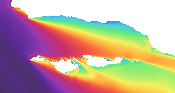
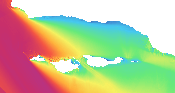

In [17]:
cmap = bcm.LinearColormap(
    SURF_COLORS, vmin=0, vmax=round(vmax, 1), caption='CDIP MOP forecast Hs (m)')

m2 = folium.Map(location=[34.15, -119.9], zoom_start=9, tiles=None,
                control_scale=True)
folium.TileLayer(
    'https://server.arcgisonline.com/ArcGIS/rest/services/Ocean/World_Ocean_Base/MapServer/tile/{z}/{y}/{x}',
    attr='Esri, GEBCO, NOAA', name='Ocean base').add_to(m2)

# Gradient as a georeferenced image per time step (light: one small PNG each,
# instead of ~12k vector markers)
for n, (vt, la, lo, hs) in enumerate(slices):
    rgba = surf_cmap(np.clip(hs / vmax, 0, 1))
    rgba[..., 3] = np.where(np.isfinite(hs), 0.9, 0.0)  # NaN = transparent
    folium.raster_layers.ImageOverlay(
        image=np.flipud((rgba * 255).astype('uint8')),  # row 0 = north
        bounds=[[float(la[0]), float(lo[0])], [float(la[-1]), float(lo[-1])]],
        name=f'Hs {vt:%a %d %H:%M}', show=(n == 0),
    ).add_to(m2)

# Tooltip-able values only near the spot (full 1 km detail where it matters)
vt0, la0, lo0, hs0 = slices[0]
near = folium.FeatureGroup(name=f'values near {SPOT["name"]} ({vt0:%a %H:%M})',
                           show=True)
ii, jj = np.nonzero(np.isfinite(hs0)
                    & (np.abs(la0[:, None] - SPOT['lat']) < 0.08)
                    & (np.abs(lo0[None, :] - SPOT['lon']) < 0.11))
for i, j in zip(ii, jj):
    folium.CircleMarker(
        [float(la0[i]), float(lo0[j])], radius=3, stroke=False, fill=True,
        fill_color=cmap(float(hs0[i, j])), fill_opacity=1.0,
        tooltip=f'{hs0[i, j]:.2f} m',
    ).add_to(near)
near.add_to(m2)

folium.Marker([SPOT['lat'], SPOT['lon']], icon=folium.Icon(color='blue', icon='star'),
              tooltip=SPOT['name']).add_to(m2)
cmap.add_to(m2)
folium.LayerControl(collapsed=False).add_to(m2)
m2.save('mop_gradient_map.html')
m2

### Maximum extent — the full MOP California grid

MOP is a CDIP *California* product: the grid spans 32°N–42°N out to 125°W and stops at
the Oregon border — that is the maximum spatial availability at 1 km. (Coverage further
north would have to come from the global models.) Same two forecast times, full grid.


Thu 09 06:00: 150,110 valid cells, Hs 0.00–3.39 m
Sat 11 06:00: 150,110 valid cells, Hs 0.00–2.56 m


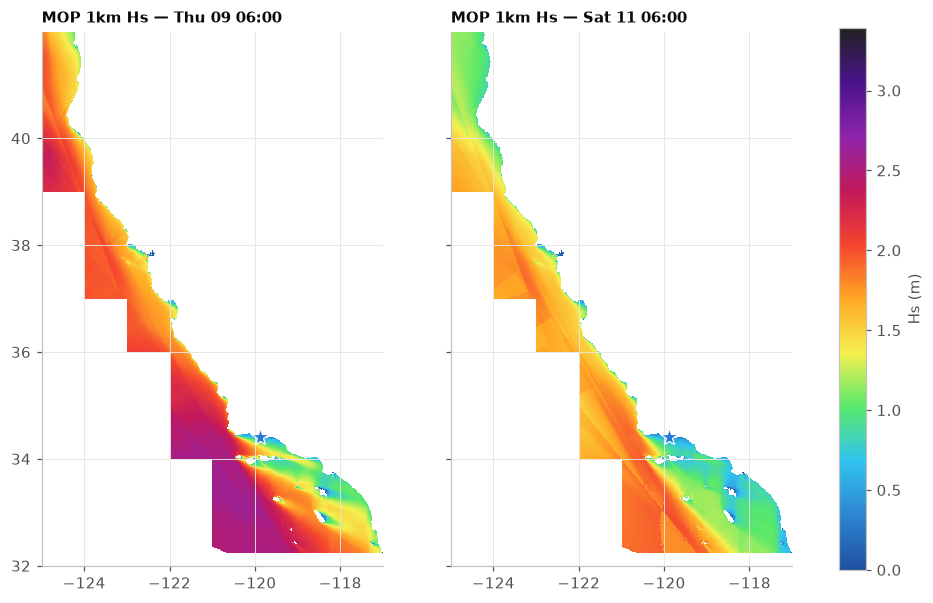

In [18]:
CA_BBOX = {'lat': (32.0, 42.0), 'lon': (-125.0, -117.0)}
ca_slices = [mop_hs_slice(when, CA_BBOX) for when in targets]
vmax_ca = float(max(np.nanmax(hs) for _, _, _, hs in ca_slices))
for vt, _, _, hs in ca_slices:
    print(f'{vt:%a %d %H:%M}: {int(np.isfinite(hs).sum()):,} valid cells, '
          f'Hs {np.nanmin(hs):.2f}–{np.nanmax(hs):.2f} m')

fig, axes = plt.subplots(1, 2, figsize=(11, 8), sharey=True)
for ax, (vt, la, lo, hs) in zip(axes, ca_slices):
    pm = ax.pcolormesh(lo, la, hs, cmap=surf_cmap, vmin=0, vmax=vmax_ca)
    for name, slat, slon in [(SPOT['name'], SPOT['lat'], SPOT['lon'])]:
        ax.plot(slon, slat, marker='*', ms=12, color='#2a78d6', mec='white', mew=0.8)
    ax.set_title(f'MOP 1km Hs — {vt:%a %d %H:%M}', loc='left',
                 fontweight='bold', fontsize=10)
    ax.set_aspect(1 / np.cos(np.radians(37.0)))
fig.colorbar(pm, ax=axes, label='Hs (m)', shrink=0.8)
plt.show()


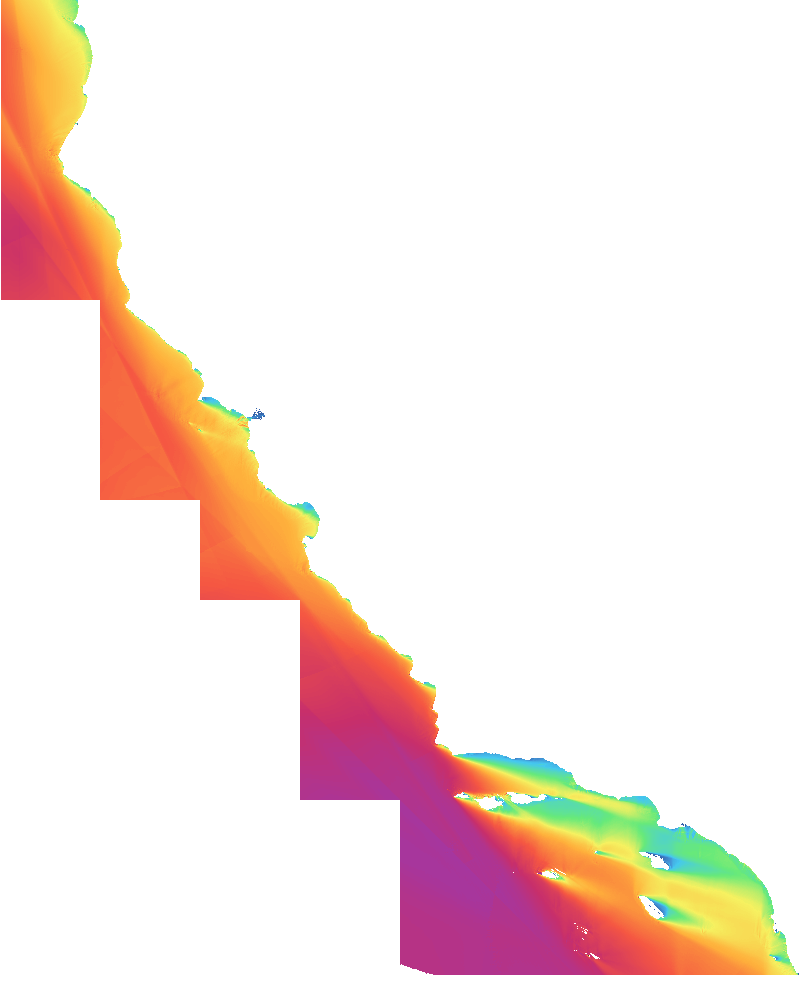
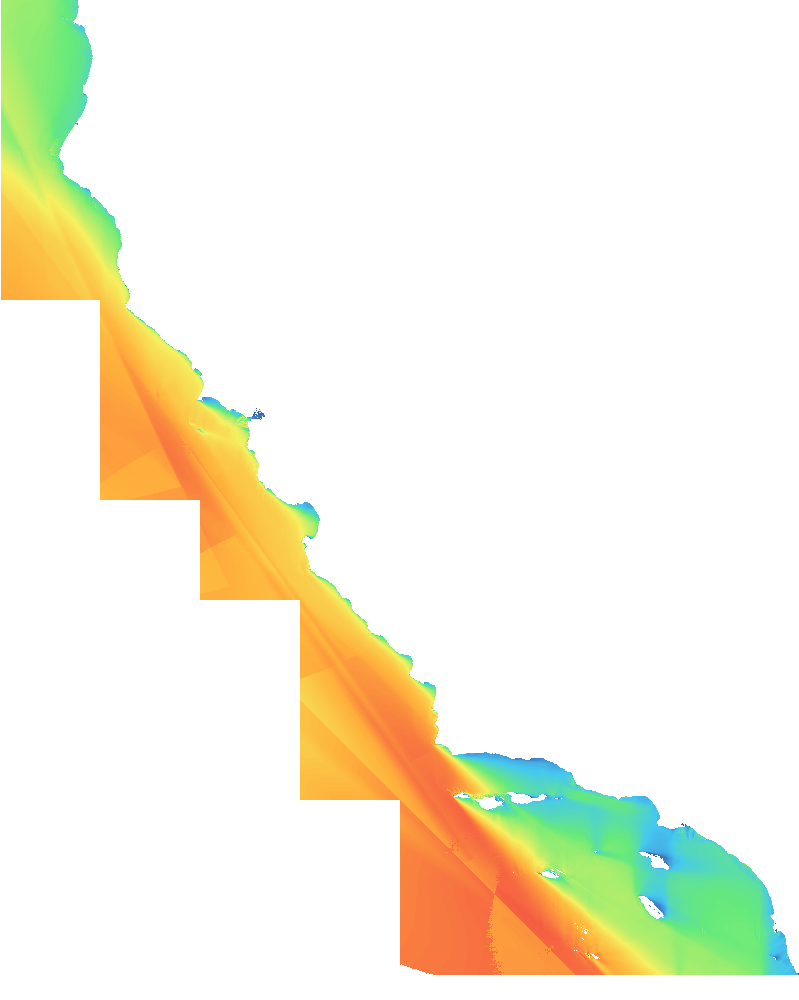

In [19]:
cmap_ca = bcm.LinearColormap(
    SURF_COLORS, vmin=0, vmax=round(vmax_ca, 1),
    caption='CDIP MOP forecast Hs (m) — full grid')

m3 = folium.Map(location=[36.3, -121.5], zoom_start=6, tiles=None,
                control_scale=True)
folium.TileLayer(
    'https://server.arcgisonline.com/ArcGIS/rest/services/Ocean/World_Ocean_Base/MapServer/tile/{z}/{y}/{x}',
    attr='Esri, GEBCO, NOAA', name='Ocean base').add_to(m3)

for n, (vt, la, lo, hs) in enumerate(ca_slices):
    rgba = surf_cmap(np.clip(hs / vmax_ca, 0, 1))
    rgba[..., 3] = np.where(np.isfinite(hs), 0.9, 0.0)
    folium.raster_layers.ImageOverlay(
        image=np.flipud((rgba * 255).astype('uint8')),
        bounds=[[float(la[0]), float(lo[0])], [float(la[-1]), float(lo[-1])]],
        name=f'Hs {vt:%a %d %H:%M}', show=(n == 0),
    ).add_to(m3)

for name, slat, slon in [('Devereaux', SPOT['lat'], SPOT['lon']),
                         ('C st.', 34.26343870100869, -119.30167128264623)]:
    folium.Marker([slat, slon], icon=folium.Icon(color='blue', icon='star'),
                  tooltip=name).add_to(m3)

cmap_ca.add_to(m3)
folium.LayerControl(collapsed=False).add_to(m3)
m3.save('mop_gradient_map_california.html')
m3

## 7. What to read from this

**Swell**
- The buoy overlap (section 4 zoom) shows which wave model tracks reality best *here*,
  behind the Channel Islands' shadow. Global models don't resolve island blocking —
  systematic over-prediction vs the buoy is expected and is the gap CDIP's ~1 km MOP
  model exists to close.
- `wave_height` (combined) vs `swell_wave_height` (primary partition, what the app
  shows today): the difference is the sea state the app currently under-reports.
- Horizons differ: MFWAM 10 d, ECMWF 15 d, GFS Wave 16 d — a longer app forecast
  would need a model switch or blend beyond day 10.

**Wind**
- GFS (25 km, current source) vs NBM (2.5 km, statistically calibrated): NBM should
  resolve the land/sea breeze cycle better. HRRR is sharpest but only covers 48 h.

**Next step for the app**: pick the display/rating sources, store the rest tagged by
model in the normalized store — each extra model is one line of adapter config.
